# Case Study: COMPAS Scorecard and Pencil-and-Paper Audit

This notebook reproduces SCORE-Net's final scorecard and individual case audit on the COMPAS (recidivism risk) dataset **entirely from training outputs**.

### Dynamically derived components

* Number of active rules and each rule's features: `final-iter-best-weights.pth` + runtime compression.
* Physical thresholds and activation formulas: model weights, `StandardScaler` parameters, and the observed range of the training data.
* Low/high-risk defendants: selected from the model's test-set predictions (most confident low risk and most confident high risk).
* Accuracy, rule counts, and comparison bars: checkpoints and `results/baselines_compas_noprot.csv`.

No rule, threshold, feature index, accuracy, or model name is hard-coded in the notebook. Under the natural constraints of COMPAS (age $\ge 18$, priors $\ge 0$), univariate rules are converted to raw physical units:

$$x_j^{\mathrm{lower}} = \mu_j + \sigma_j \left(\frac{c_h - w_h}{W_{f, hj}}\right), \qquad x_j^{\mathrm{upper}} = \mu_j + \sigma_j \left(\frac{c_h + w_h}{W_{f, hj}}\right)$$

> **Run order:** COMPAS training notebook → `notebooks/01_baselines.ipynb` → this notebook.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Locate the project root regardless of the notebook's working directory.
cwd = Path.cwd().resolve()
project_root = next(
    (path for path in [cwd, *cwd.parents] if (path / "utils" / "experiments.py").exists()),
    cwd.parent,
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from utils.reproducibility import set_seed
from utils.experiments import (
    DATASETS,
    compact_model,
    describe_rule,
    load_baselines,
    load_checkpoint,
    load_splits,
    practical_rule_text,
    save_figure,
)

set_seed(42)

device = "cpu"
split = load_splits("compas_noprot")
feature_names = split.feature_names
train_loader = split.loader("train")

model_final = compact_model(
    load_checkpoint(DATASETS["compas_noprot"].final_checkpoint, device=device), train_loader
)
model_global = compact_model(
    load_checkpoint(DATASETS["compas_noprot"].global_checkpoint, device=device), train_loader
)

with torch.no_grad():
    acc_final = float(
        (model_final(split.X_test).argmax(dim=1) == split.y_test).float().mean()
    ) * 100.0
    acc_global = float(
        (model_global(split.X_test).argmax(dim=1) == split.y_test).float().mean()
    ) * 100.0

raw_train = split.scaler.inverse_transform(split.X_train.cpu().numpy())
raw_min = raw_train.min(axis=0)
raw_max = raw_train.max(axis=0)

print("COMPAS dataset loaded:")
print(f"  Train: {split.X_train.shape[0]} samples | Validation: {split.X_val.shape[0]} | Test: {split.X_test.shape[0]}")
print(f"  Feature count: {split.n_features} | Class count: {split.n_classes}")
print(f"  Final compact model: {model_final.H} rules | Test accuracy: %{acc_final:.2f}")
print(f"  Global best model       : {model_global.H} rules | Test accuracy: %{acc_global:.2f}")

COMPAS dataset loaded:
  Train: 5193 samples | Validation: 578 | Test: 1443
  Feature count: 7 | Class count: 2
  Final compact model: 3 rules | Test accuracy: %66.67
  Global best model       : 25 rules | Test accuracy: %68.68


In [2]:
# ==============================================================================
# 1. DERIVING RULES IN STANDARDIZED (z) AND RAW PHYSICAL UNITS
# ==============================================================================
W_f = model_final.feature_linear.weight.detach().cpu().numpy()
W_o = model_final.output_linear.weight.detach().cpu().numpy()
b_o = model_final.output_linear.bias.detach().cpu().numpy()
centers = model_final.base_feature_center.detach().cpu().numpy()
widths = torch.abs(model_final.base_feature_width).detach().cpu().numpy() + 1e-8

descriptions = []
derivation_records = []

for h in range(model_final.H):
    desc = describe_rule(
        W_f[h], centers[h], widths[h], feature_names, split.scaler, threshold=1e-4
    )
    desc["rule_index"] = h
    desc["practical"] = practical_rule_text(desc, raw_min, raw_max, decimals=1)
    descriptions.append(desc)

    if desc["is_single"]:
        j = desc["indices"][0]
        derivation_records.append({
            "Rule": f"R_{h + 1}",
            "Feature": desc["feature_names"][0],
            "z Range": f"[{centers[h] - widths[h]:.2f}, {centers[h] + widths[h]:.2f}]",
            "mu / sigma": f"{split.scaler.mean_[j]:.1f} / {split.scaler.scale_[j]:.1f}",
            "Raw Range": f"[{desc['low_raw']:.2f}, {desc['high_raw']:.2f}]",
            "Peak": f"{desc['peak_raw']:.1f}",
            "Practical Rule Condition": desc["practical"],
        })
    else:
        derivation_records.append({
            "Rule": f"R_{h + 1}",
            "Feature": ", ".join(desc["feature_names"]),
            "z Range": f"[{desc['center'] - desc['width']:.2f}, {desc['center'] + desc['width']:.2f}]",
            "mu / sigma": "Multiple features",
            "Raw Range": "Oblique slab",
            "Peak": f"Center={desc['center']:.2f}",
            "Practical Rule Condition": desc["practical"],
        })

df_deriv = pd.DataFrame(derivation_records)
print("=" * 100)
print("DERIVATION OF SCORE-NET RULES IN STANDARDIZED (z) AND RAW PHYSICAL UNITS")
print("=" * 100)
print(df_deriv.to_string(index=False))

DERIVATION OF SCORE-NET RULES IN STANDARDIZED (z) AND RAW PHYSICAL UNITS
Rule        Feature        z Range  mu / sigma      Raw Range Peak Practical Rule Condition
 R_1   priors_count  [-0.06, 0.54]   3.5 / 4.9  [-4.24, 4.29]  0.0      priors_count <= 4.3
 R_2 juv_misd_count  [-0.19, 0.39]   0.1 / 0.4  [-0.08, 0.41]  0.2    juv_misd_count <= 0.4
 R_3            age [-0.58, -0.23] 34.8 / 11.9 [11.64, 25.62] 18.6              age <= 25.6


In [3]:
# ==============================================================================
# 2. SCORECARD ENGINE: PHYSICAL TRIGGER AND VOTES FOR EACH RULE
# ==============================================================================
engine_rows = []

for h, desc in enumerate(descriptions):
    if desc["is_single"]:
        feature_text = desc["feature_names"][0]
    else:
        feature_text = " + ".join(desc["feature_names"]) + " (oblique)"

    vote_norec = float(W_o[0, h])
    vote_rec = float(W_o[1, h])
    comment = (
        "Increases recidivism risk"
        if vote_rec > vote_norec
        else "Protective vote toward no recidivism"
    )

    engine_rows.append({
        "Rule": f"R_{h + 1}",
        "Feature": feature_text,
        "Physical Trigger": desc["practical"],
        "Activation Formula a_h(x)": desc["formula"],
        "Low-Risk Vote (NoRec)": f"{vote_norec:+.3f}",
        "High-Risk Vote (Recid)": f"{vote_rec:+.3f}",
        "Comment": comment,
    })

engine_rows.append({
    "Rule": "Bias",
    "Feature": "Constant offset",
    "Physical Trigger": "Base prior",
    "Activation Formula a_h(x)": "Constant a = 1.0",
    "Low-Risk Vote (NoRec)": f"{b_o[0]:+.3f}",
    "High-Risk Vote (Recid)": f"{b_o[1]:+.3f}",
    "Comment": "Base class probabilities in the training set",
})

df_engine = pd.DataFrame(engine_rows)
print(f"\n--- COMPAS {model_final.H}-RULE SCORE-NET SCORECARD ENGINE ---")
print(df_engine.to_string(index=False))


--- COMPAS 3-RULE SCORE-NET SCORECARD ENGINE ---
Rule         Feature      Physical Trigger                  Activation Formula a_h(x) Low-Risk Vote (NoRec) High-Risk Vote (Recid)                                      Comment
 R_1    priors_count   priors_count <= 4.3   max(0, 1 - |priors_count - 0.02| / 4.27)                +0.594                 -0.727         Protective vote toward no recidivism
 R_2  juv_misd_count juv_misd_count <= 0.4 max(0, 1 - |juv_misd_count - 0.17| / 0.24)                +0.227                 -0.275         Protective vote toward no recidivism
 R_3             age           age <= 25.6           max(0, 1 - |age - 18.63| / 6.99)                -0.828                 +0.797                    Increases recidivism risk
Bias Constant offset            Base prior                           Constant a = 1.0                -0.227                 +0.171 Base class probabilities in the training set


In [4]:
# ==============================================================================
# 3. INDIVIDUAL CASE AUDIT: LOW- AND HIGH-RISK DEFENDANTS
# ==============================================================================
X_test = split.X_test
y_test = split.y_test

with torch.no_grad():
    logits_all = model_final(X_test)
    margins_all = logits_all[:, 1] - logits_all[:, 0]
    preds_all = logits_all.argmax(dim=1)

low_candidates = torch.where(preds_all == 0)[0]
high_candidates = torch.where(preds_all == 1)[0]
if len(low_candidates) == 0 or len(high_candidates) == 0:
    raise RuntimeError(
        "Both classes are missing from the COMPAS test predictions; "
        "the case study needs at least one low-risk and one high-risk defendant."
    )

# Most confident low risk: largest margin for class 0 (most negative s1 - s0).
low_idx = int(low_candidates[torch.argmin(margins_all[low_candidates])])
# Most confident high risk: largest margin for class 1.
high_idx = int(high_candidates[torch.argmax(margins_all[high_candidates])])


def signed(value, digits=2):
    """Signed formatting; avoids negative zero (``-0.00``)."""
    return f"{round(float(value), digits) + 0.0:+.{digits}f}"


def signed2(value):
    """Signed two-decimal formatting (shortcut for figures)."""
    return signed(value, 2)


def audit_record(index):
    x_vec = X_test[index:index + 1]
    raw_vec = split.scaler.inverse_transform(x_vec.cpu().numpy())[0]

    with torch.no_grad():
        h_proj = (
            model_final.feature_linear.weight @ x_vec.T
        ).squeeze(0).reshape(-1).cpu().numpy()
        logits_model = model_final(x_vec).squeeze(0).reshape(-1).cpu().numpy()

    activations = []
    contributions = []
    for h in range(model_final.H):
        diff = abs(centers[h] - h_proj[h])
        act = max(0.0, (widths[h] - diff) / widths[h])
        activations.append(act)
        contributions.append((float(W_o[0, h] * act), float(W_o[1, h] * act)))

    total = (
        float(b_o[0]) + sum(c[0] for c in contributions),
        float(b_o[1]) + sum(c[1] for c in contributions),
    )
    diff_err = max(abs(total[0] - logits_model[0]), abs(total[1] - logits_model[1]))
    if diff_err > 1e-5:
        raise AssertionError(
            f"Pencil-and-paper calculation does not match the model output: {diff_err:.3e}"
        )

    return {
        "index": int(index),
        "x_vec": x_vec.squeeze(0).cpu().numpy(),
        "raw_vec": raw_vec,
        "logits": logits_model,
        "activations": activations,
        "contributions": contributions,
        "total": total,
        "pred": int(np.argmax(total)),
        "true": int(y_test[index]),
        "margin": abs(total[1] - total[0]),
    }


audit_low = audit_record(low_idx)
audit_high = audit_record(high_idx)

for label, audit in [("LOW RISK", audit_low), ("HIGH RISK", audit_high)]:
    print("=" * 70)
    print(f"{label} DEFENDANT #{audit['index']}")
    print(f"True label: {'Recidivism' if audit['true'] == 1 else 'No Recidivism'}")
    print("=" * 70)
    for h in range(model_final.H):
        act = audit["activations"][h]
        c0, c1 = audit["contributions"][h]
        status = f"Fires (a_{h + 1}={act:.3f})" if act > 0 else "Inactive (0.000)"
        print(
            f"  -> Rule R_{h + 1}: {status:28s} | "
            f"Contribution: NoRec={signed(c0, 3)}, Recid={signed(c1, 3)}"
        )
    print(
        f"  [TOTAL] NoRec={signed(audit['total'][0], 4)} | "
        f"Recid={signed(audit['total'][1], 4)}"
    )
    print(
        f"  [MODEL ] NoRec={signed(audit['logits'][0], 4)} | "
        f"Recid={signed(audit['logits'][1], 4)}"
    )
    verdict = (
        "NO RECIDIVISM (Low Risk)"
        if audit["pred"] == 0
        else "RECIDIVISM (High Risk)"
    )
    print(f"  [VERDICT] >>> {verdict} <<<\n")

LOW RISK DEFENDANT #6
True label: No Recidivism
  -> Rule R_1: Fires (a_1=0.995)            | Contribution: NoRec=+0.591, Recid=-0.723
  -> Rule R_2: Fires (a_2=0.312)            | Contribution: NoRec=+0.071, Recid=-0.086
  -> Rule R_3: Inactive (0.000)             | Contribution: NoRec=+0.000, Recid=+0.000
  [TOTAL] NoRec=+0.4345 | Recid=-0.6378
  [MODEL ] NoRec=+0.4345 | Recid=-0.6378
  [VERDICT] >>> NO RECIDIVISM (Low Risk) <<<

HIGH RISK DEFENDANT #839
True label: Recidivism
  -> Rule R_1: Inactive (0.000)             | Contribution: NoRec=+0.000, Recid=+0.000
  -> Rule R_2: Inactive (0.000)             | Contribution: NoRec=+0.000, Recid=+0.000
  -> Rule R_3: Fires (a_3=0.947)            | Contribution: NoRec=-0.785, Recid=+0.754
  [TOTAL] NoRec=-1.0119 | Recid=+0.9253
  [MODEL ] NoRec=-1.0119 | Recid=+0.9253
  [VERDICT] >>> RECIDIVISM (High Risk) <<<



Figure saved: /home/ahmet/Projects/ScoreNetSingle/paper/neurocomputing/figures/fig_compas_pencil_paper_scorecard.pdf and /home/ahmet/Projects/ScoreNetSingle/paper/neurocomputing/figures/fig_compas_pencil_paper_scorecard.png


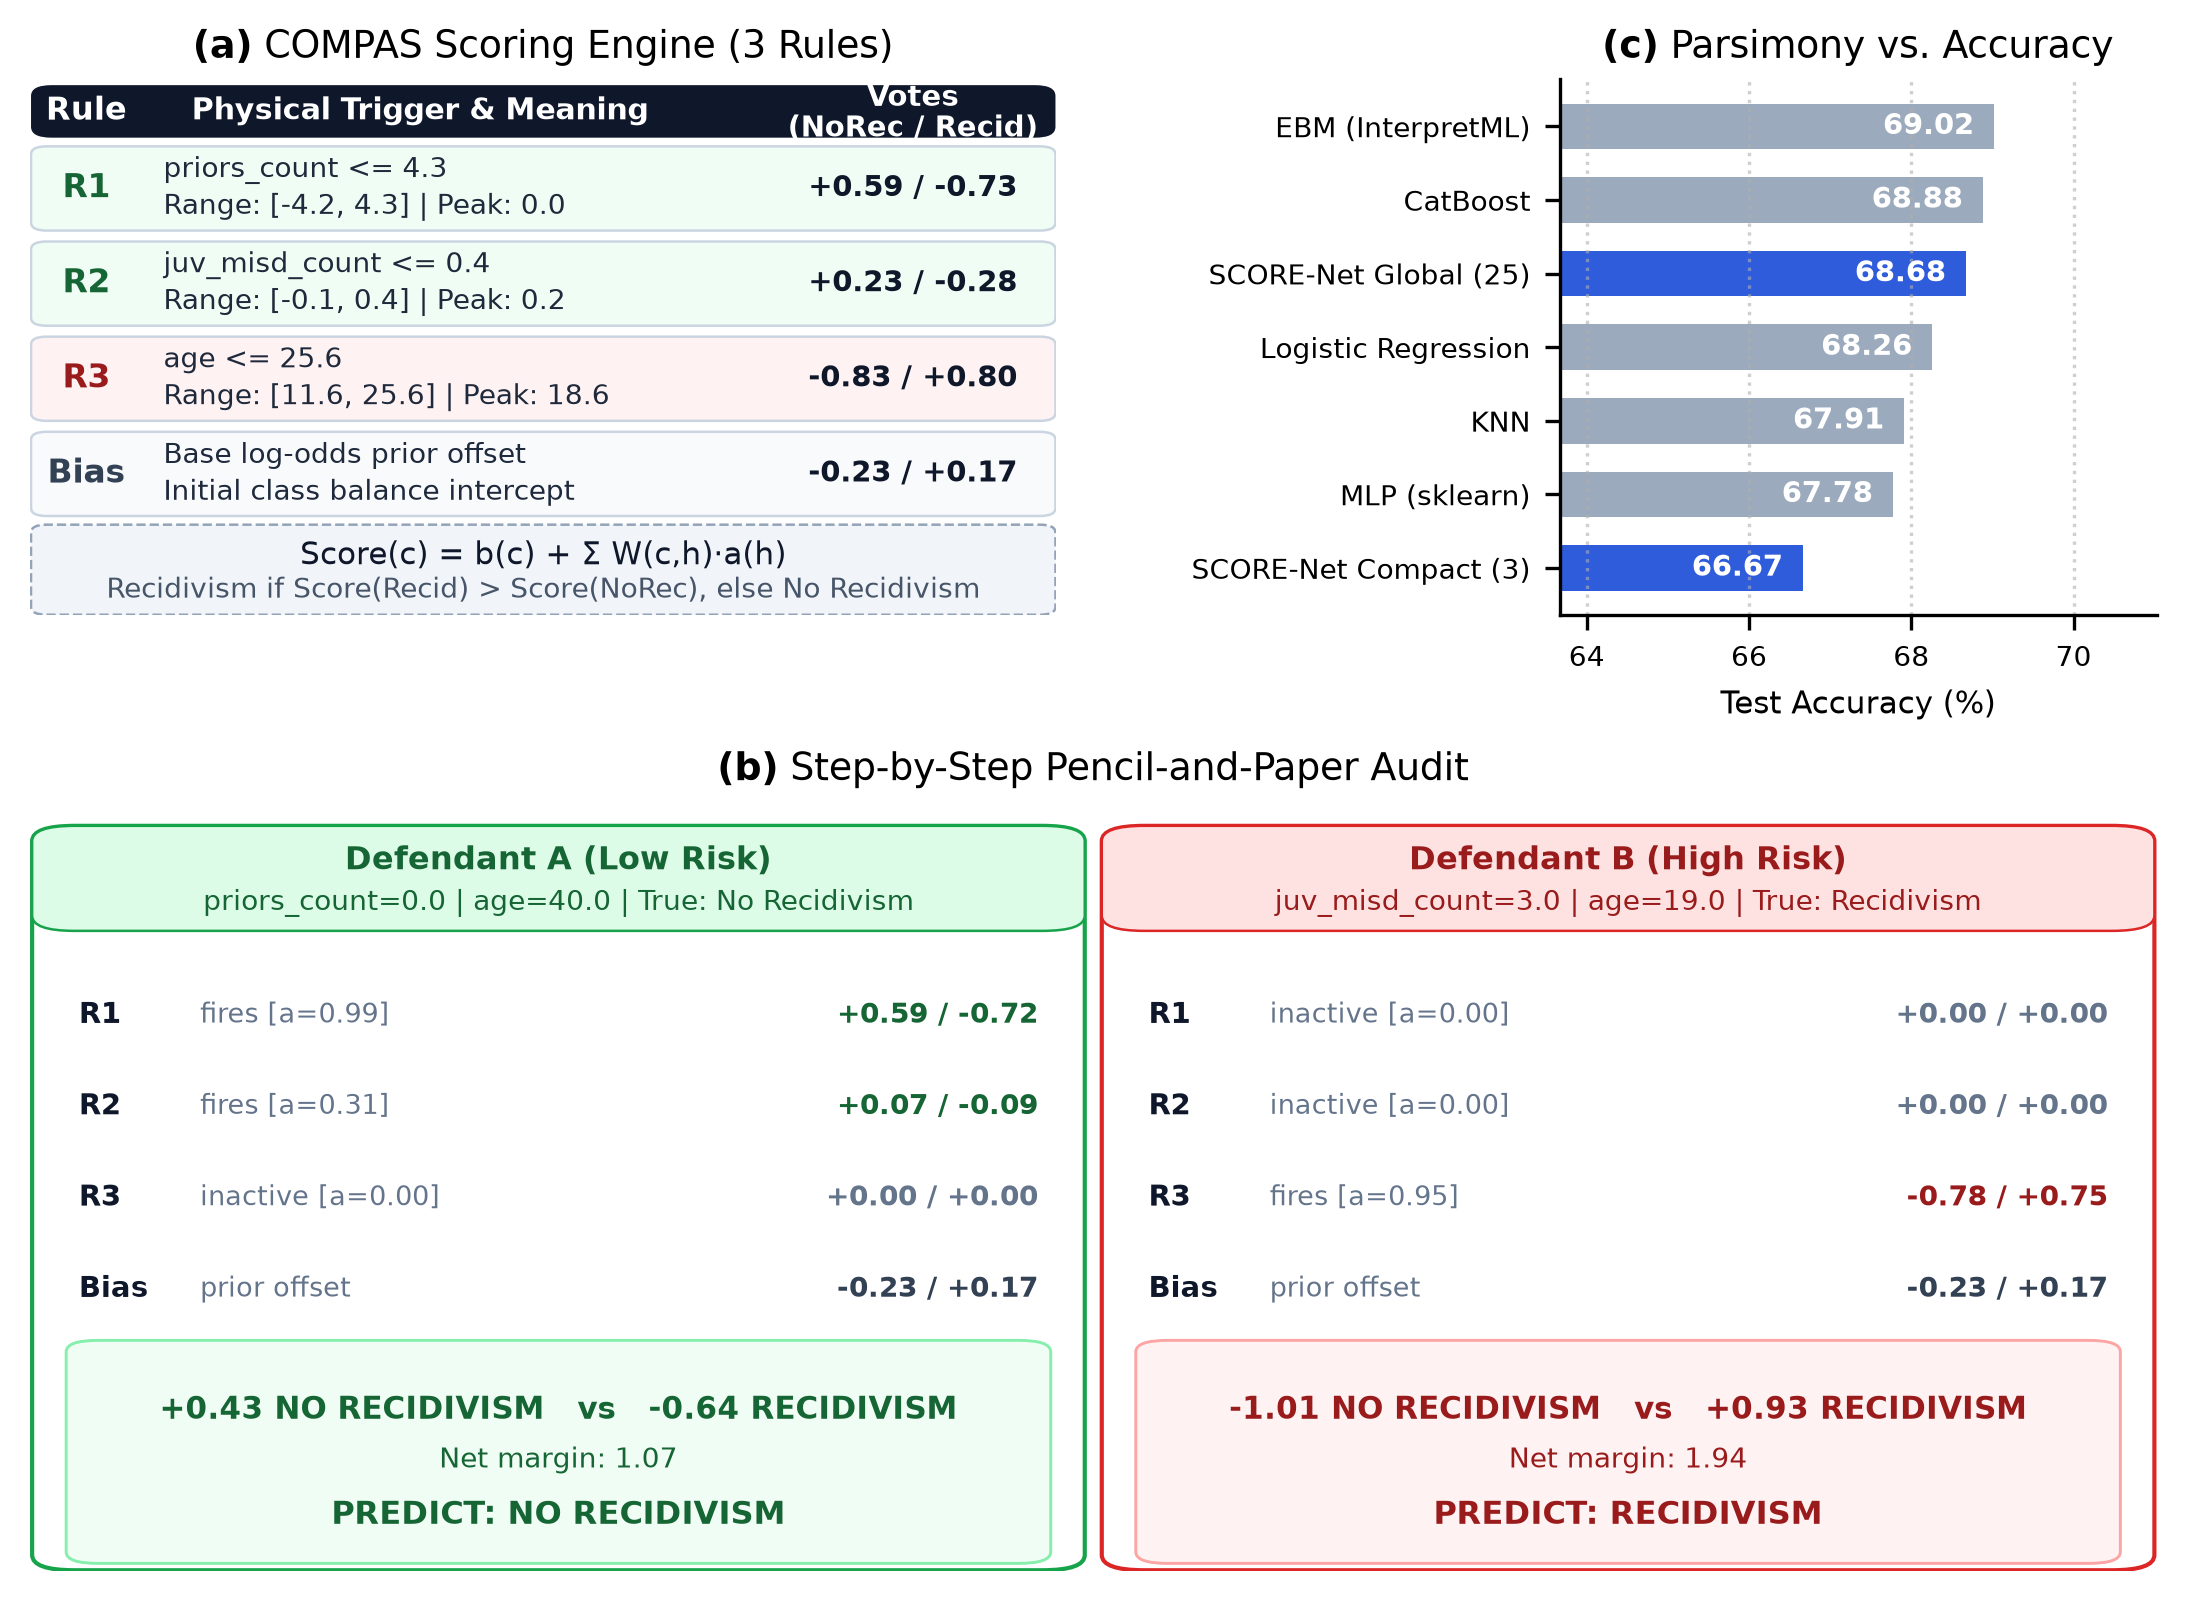

In [5]:
# ==============================================================================
# 4. PENCIL-AND-PAPER COMPAS SCORECARD FIGURE
# ==============================================================================
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial"],
    "font.size": 7.6,
    "axes.titlesize": 9.0,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

n_rows = model_final.H + 1  # rules + bias
FIG_W = 7.16
FIG_H = max(5.85, 4.4 + 0.22 * n_rows)
fig = plt.figure(figsize=(FIG_W, FIG_H), dpi=300)
gs = fig.add_gridspec(
    2, 2, width_ratios=[1.72, 1.0], height_ratios=[1.0, 1.42],
    wspace=0.62, hspace=0.30,
    left=0.005, right=0.995, top=0.935, bottom=0.085,
)

# ---------------------------------------------------------------
# Panel (a): Dynamic scorecard engine
# ---------------------------------------------------------------
ax1 = fig.add_subplot(gs[0, 0])
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1)
ax1.axis("off")
ax1.set_title(r"$\mathbf{(a)}$ COMPAS Scoring Engine (%d Rules)" % model_final.H, pad=5)

header_h = 0.09
footer_h = 0.16
top = 0.985
body_top = top - header_h - 0.01
body_bottom = 0.005 + footer_h + 0.01
row_h = (body_top - body_bottom) / n_rows

ax1.add_patch(FancyBboxPatch(
    (0.005, top - header_h), 0.99, header_h,
    boxstyle="round,pad=0.004,rounding_size=0.02",
    facecolor="#0F172A", edgecolor="none",
))
ax1.text(0.055, top - header_h / 2, "Rule", color="white", fontweight="bold", fontsize=7.6, va="center", ha="center")
ax1.text(0.38, top - header_h / 2, "Physical Trigger & Meaning", color="white", fontweight="bold", fontsize=7.2, va="center", ha="center")
ax1.text(
    0.86, top - header_h / 2, "Votes\n(NoRec / Recid)", color="white",
    fontweight="bold", fontsize=7.0, va="center", ha="center", linespacing=1.1,
)

row_specs = []
for h, desc in enumerate(descriptions):
    if desc["is_single"]:
        meaning = (
            f"{desc['practical']}\n"
            f"Range: [{desc['low_raw']:.1f}, {desc['high_raw']:.1f}] | "
            f"Peak: {desc['peak_raw']:.1f}"
        )
    else:
        names = desc["feature_names"]
        shown = ", ".join(names[:2]) + (" ..." if len(names) > 2 else "")
        meaning = f"Oblique slab: {shown}\n{len(names)}-feature interaction"

    vote_norec = float(W_o[0, h])
    vote_rec = float(W_o[1, h])
    row_specs.append({
        "name": f"R{h + 1}",
        "meaning": meaning,
        "votes": f"{signed2(vote_norec)} / {signed2(vote_rec)}",
        "bg": "#FEF2F2" if vote_rec > vote_norec else "#F0FDF4",
        "fg": "#991B1B" if vote_rec > vote_norec else "#166534",
    })

row_specs.append({
    "name": "Bias",
    "meaning": "Base log-odds prior offset\nInitial class balance intercept",
    "votes": f"{signed2(b_o[0])} / {signed2(b_o[1])}",
    "bg": "#F8FAFC",
    "fg": "#334155",
})

for i, spec in enumerate(row_specs):
    y = body_top - (i + 1) * row_h
    pad = row_h * 0.08
    ax1.add_patch(FancyBboxPatch(
        (0.005, y + pad), 0.99, row_h - 2 * pad,
        boxstyle="round,pad=0.004,rounding_size=0.015",
        facecolor=spec["bg"], edgecolor="#CBD5E1", linewidth=0.6,
    ))
    cy = y + row_h / 2
    ax1.text(0.055, cy, spec["name"], color=spec["fg"], fontweight="bold", fontsize=8.0, va="center", ha="center")
    ax1.text(0.13, cy, spec["meaning"], color="#1E293B", fontsize=6.8, va="center", ha="left", linespacing=1.3)
    ax1.text(0.86, cy, spec["votes"], color="#0F172A", fontweight="bold", fontsize=7.0, va="center", ha="center")

ax1.add_patch(FancyBboxPatch(
    (0.005, 0.005), 0.99, footer_h,
    boxstyle="round,pad=0.004,rounding_size=0.015",
    facecolor="#F1F5F9", edgecolor="#94A3B8", linestyle="--", linewidth=0.6,
))
ax1.text(
    0.5, 0.005 + footer_h * 0.66,
    "Score(c) = b(c) + \u03a3 W(c,h)\u00b7a(h)",
    ha="center", va="center", fontsize=7.4, color="#0F172A",
)
ax1.text(
    0.5, 0.005 + footer_h * 0.26,
    "Recidivism if Score(Recid) > Score(NoRec), else No Recidivism",
    ha="center", va="center", fontsize=6.8, color="#475569",
)

# ---------------------------------------------------------------
# Panel (c): Parsimony vs. accuracy (from baseline CSV)
# ---------------------------------------------------------------
ax3 = fig.add_subplot(gs[0, 1])
ax3.set_title(r"$\mathbf{(c)}$ Parsimony vs. Accuracy", pad=5)

comparison_rows = [
    {
        "Model": f"SCORE-Net Global ({model_global.H})",
        "Accuracy (%)": acc_global,
        "Source": "SCORE-Net",
    },
    {
        "Model": f"SCORE-Net Compact ({model_final.H})",
        "Accuracy (%)": acc_final,
        "Source": "SCORE-Net",
    },
]
try:
    baseline_df = load_baselines("compas_noprot")
    top_baselines = baseline_df.nlargest(5, "Accuracy (%)").copy()
    top_baselines["Source"] = "Baseline"
    comparison_rows.extend(
        top_baselines[["Model", "Accuracy (%)", "Source"]].to_dict("records")
    )
except FileNotFoundError as exc:
    print(f"Warning: {exc}")
    print("Panel (c) will be drawn with SCORE-Net variants only.")

comparison_df = (
    pd.DataFrame(comparison_rows)
    .sort_values("Accuracy (%)", ascending=True)
    .reset_index(drop=True)
)
colors = [
    "#1D4ED8" if source == "SCORE-Net" else "#94A3B8"
    for source in comparison_df["Source"]
]
y_pos = np.arange(len(comparison_df))
bars = ax3.barh(
    y_pos, comparison_df["Accuracy (%)"], color=colors,
    height=0.62, edgecolor="none", alpha=0.92,
)
for bar, acc in zip(bars, comparison_df["Accuracy (%)"]):
    ax3.text(
        bar.get_width() - 0.25, bar.get_y() + bar.get_height() / 2,
        f"{acc:.2f}", ha="right", va="center", color="white",
        fontweight="bold", fontsize=7.0,
    )
ax3.set_yticks(y_pos)
ax3.set_yticklabels(comparison_df["Model"], fontsize=6.8)
ax3.set_xlim(
    max(0, comparison_df["Accuracy (%)"].min() - 3),
    comparison_df["Accuracy (%)"].max() + 2,
)
ax3.set_xlabel("Test Accuracy (%)", fontsize=7.4)
ax3.tick_params(axis="x", labelsize=6.8)
ax3.grid(axis="x", linestyle=":", alpha=0.6)
ax3.spines["top"].set_visible(False)
ax3.spines["right"].set_visible(False)

# ---------------------------------------------------------------
# Panel (b): Step-by-step pencil-and-paper audit
# ---------------------------------------------------------------
ax2 = fig.add_subplot(gs[1, :])
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1)
ax2.axis("off")
ax2.set_title(r"$\mathbf{(b)}$ Step-by-Step Pencil-and-Paper Audit", pad=7)


def defendant_subtitle(audit):
    used = []
    for desc in descriptions:
        for j in desc["indices"]:
            if j not in used:
                used.append(j)
    used = sorted(used, key=lambda j: abs(audit["x_vec"][j]), reverse=True)[:2]
    parts = [f"{feature_names[j]}={audit['raw_vec'][j]:.1f}" for j in used]
    true_label = "Recidivism" if audit["true"] == 1 else "No Recidivism"
    return " | ".join(parts) + f" | True: {true_label}"


def draw_card(x0, audit, title, title_bg, title_fg, border, tally_bg, tally_edge):
    card_w = 0.487
    ax2.add_patch(FancyBboxPatch(
        (x0, 0.005), card_w, 0.97,
        boxstyle="round,pad=0.004,rounding_size=0.02",
        facecolor="#FFFFFF", edgecolor=border, linewidth=1.0,
    ))
    ax2.add_patch(FancyBboxPatch(
        (x0, 0.845), card_w, 0.13,
        boxstyle="round,pad=0.004,rounding_size=0.02",
        facecolor=title_bg, edgecolor=border, linewidth=0.6,
    ))
    ax2.text(x0 + card_w / 2, 0.933, title, color=title_fg, fontweight="bold", fontsize=7.8, ha="center", va="center")
    ax2.text(x0 + card_w / 2, 0.878, defendant_subtitle(audit), color=title_fg, fontsize=6.8, ha="center", va="center")

    item_top = 0.79
    item_bottom = 0.31
    step = (item_top - item_bottom) / n_rows
    for i in range(model_final.H):
        act = audit["activations"][i]
        c0, c1 = audit["contributions"][i]
        if act > 0:
            cond = f"fires [a={act:.2f}]"
            col = "#991B1B" if W_o[1, i] > W_o[0, i] else "#166534"
        else:
            cond = "inactive [a=0.00]"
            col = "#64748B"
        y = item_top - (i + 0.5) * step
        ax2.text(x0 + 0.018, y, f"R{i + 1}", fontweight="bold", fontsize=7.0, color="#0F172A", va="center")
        ax2.text(x0 + 0.075, y, cond, fontsize=6.6, color="#64748B", va="center")
        ax2.text(x0 + card_w - 0.018, y, f"{signed2(c0)} / {signed2(c1)}", fontsize=6.8, color=col, fontweight="bold", ha="right", va="center")

    y_bias = item_top - (model_final.H + 0.5) * step
    ax2.text(x0 + 0.018, y_bias, "Bias", fontweight="bold", fontsize=7.0, color="#0F172A", va="center")
    ax2.text(x0 + 0.075, y_bias, "prior offset", fontsize=6.6, color="#64748B", va="center")
    ax2.text(x0 + card_w - 0.018, y_bias, f"{signed2(b_o[0])} / {signed2(b_o[1])}", fontsize=6.8, color="#334155", fontweight="bold", ha="right", va="center")

    ax2.add_patch(FancyBboxPatch(
        (x0 + 0.016, 0.014), card_w - 0.032, 0.285,
        boxstyle="round,pad=0.004,rounding_size=0.015",
        facecolor=tally_bg, edgecolor=tally_edge, linewidth=0.7,
    ))
    cx = x0 + card_w / 2
    total_line = (
        f"{signed2(audit['total'][0])} NO RECIDIVISM   vs   "
        f"{signed2(audit['total'][1])} RECIDIVISM"
    )
    margin_line = f"Net margin: {audit['margin']:.2f}"
    verdict = "PREDICT: NO RECIDIVISM" if audit["pred"] == 0 else "PREDICT: RECIDIVISM"
    ax2.text(cx, 0.200, total_line, color=title_fg, fontweight="bold", fontsize=7.4, ha="center")
    ax2.text(cx, 0.136, margin_line, color=title_fg, fontsize=6.8, ha="center")
    ax2.text(cx, 0.062, verdict, color=title_fg, fontweight="bold", fontsize=7.8, ha="center")


draw_card(0.005, audit_low, "Defendant A (Low Risk)", "#DCFCE7", "#166534", "#16A34A", "#F0FDF4", "#86EFAC")
draw_card(0.508, audit_high, "Defendant B (High Risk)", "#FEE2E2", "#991B1B", "#DC2626", "#FEF2F2", "#FCA5A5")

save_figure(fig, "fig_compas_pencil_paper_scorecard")
plt.show()

In [6]:
# ==============================================================================
# 5. LATEX TABLES FOR THE PAPER (DYNAMIC)
# ==============================================================================
def tex_escape(text):
    replacements = {
        "\\": r"\textbackslash{}",
        "&": r"\&",
        "%": r"\%",
        "$": r"\$",
        "#": r"\#",
        "_": r"\_",
        "{": r"\{",
        "}": r"\}",
        "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}",
    }
    return "".join(replacements.get(ch, ch) for ch in str(text))


rule_lines = []
for h, desc in enumerate(descriptions):
    peak = f"{desc['peak_raw']:.1f}" if desc["is_single"] else "Oblique"
    rule_lines.append(
        f"$R_{{{h + 1}}}$ & \\texttt{{{tex_escape(desc['practical'])}}} & "
        f"\\texttt{{{tex_escape(desc['formula'])}}} & {peak} & "
        f"{W_o[0, h]:+.3f} & {W_o[1, h]:+.3f} \\\\"
    )

latex_rules_table = (
    "\\begin{table}[t]\n"
    "\\centering\n"
    f"\\caption{{Complete {model_final.H}-Rule Scorecard Architecture of \\modelname{{}} on COMPAS "
    f"({acc_final:.2f}\\% Test Accuracy, Evaluated by Hand in 30 Seconds).}}\n"
    "\\label{tab:compas_scorecard_rules}\n"
    "\\resizebox{\\columnwidth}{!}{%\n"
    "\\begin{tabular}{cllccc}\n"
    "\\toprule\n"
    "\\textbf{Rule} & \\textbf{Physical Trigger} & \\textbf{Activation Formula $a_h(x)$} & "
    "\\textbf{Peak Center} & \\textbf{No Recidivism} & \\textbf{Recidivism} \\\\\n"
    "\\midrule\n"
    + "\n".join(rule_lines) + "\n"
    "\\midrule\n"
    f"\\textbf{{Bias}} & Baseline prior & Absorbed bias shift ($b_o$) & -- & "
    f"{b_o[0]:+.3f} & {b_o[1]:+.3f} \\\\\n"
    "\\bottomrule\n"
    "\\end{tabular}%\n"
    "}\n"
    "\\end{table}"
)


def audit_cell(audit, h):
    act = audit["activations"][h]
    c0, c1 = audit["contributions"][h]
    if act <= 0:
        return "Inactive $\\to 0.00$"
    return f"Fires ($a_{{{h + 1}}}={act:.2f}$) $\\to {signed2(c0)}\\;/\\;{signed2(c1)}$"


audit_lines = []
for h, desc in enumerate(descriptions):
    audit_lines.append(
        f"Rule $R_{{{h + 1}}}$ & {audit_cell(audit_low, h)} & "
        f"{audit_cell(audit_high, h)} \\\\"
    )

low_verdict = "NO RECIDIVISM" if audit_low["pred"] == 0 else "RECIDIVISM"
high_verdict = "NO RECIDIVISM" if audit_high["pred"] == 0 else "RECIDIVISM"

latex_hand_audit_table = (
    "\\begin{table}[t]\n"
    "\\centering\n"
    "\\caption{Exact Step-by-Step Pencil-and-Paper Audit for Two Contrasting Defendants from the COMPAS Benchmark.}\n"
    "\\label{tab:compas_hand_audit}\n"
    "\\resizebox{\\columnwidth}{!}{%\n"
    "\\begin{tabular}{lll}\n"
    "\\toprule\n"
    "\\textbf{Evaluation Step} & \\textbf{Defendant A (Low Risk)} & \\textbf{Defendant B (High Risk)} \\\\\n"
    "\\midrule\n"
    f"\\textbf{{Features}} & {tex_escape(defendant_subtitle(audit_low))} & {tex_escape(defendant_subtitle(audit_high))} \\\\\n"
    "\\midrule\n"
    + "\n".join(audit_lines) + "\n"
    "\\midrule\n"
    f"\\textbf{{Logit Tally}} & NoRec: \\textbf{{{signed2(audit_low['total'][0])}}}, Recid: \\textbf{{{signed2(audit_low['total'][1])}}} & "
    f"NoRec: \\textbf{{{signed2(audit_high['total'][0])}}}, Recid: \\textbf{{{signed2(audit_high['total'][1])}}} \\\\\n"
    f"\\textbf{{Net Margin}} & $\\Delta s = {audit_low['margin']:.2f}$ & $\\Delta s = {audit_high['margin']:.2f}$ \\\\\n"
    f"\\textbf{{Final Verdict}} & \\textbf{{{low_verdict}}} & \\textbf{{{high_verdict}}} \\\\\n"
    "\\bottomrule\n"
    "\\end{tabular}%\n"
    "}\n"
    "\\end{table}"
)

print("=== LATEX TABLE 1: COMPAS SCORECARD RULES ===")
print(latex_rules_table)
print("\n=== LATEX TABLE 2: PENCIL-AND-PAPER AUDIT ===")
print(latex_hand_audit_table)

=== LATEX TABLE 1: COMPAS SCORECARD RULES ===
\begin{table}[t]
\centering
\caption{Complete 3-Rule Scorecard Architecture of \modelname{} on COMPAS (66.67\% Test Accuracy, Evaluated by Hand in 30 Seconds).}
\label{tab:compas_scorecard_rules}
\resizebox{\columnwidth}{!}{%
\begin{tabular}{cllccc}
\toprule
\textbf{Rule} & \textbf{Physical Trigger} & \textbf{Activation Formula $a_h(x)$} & \textbf{Peak Center} & \textbf{No Recidivism} & \textbf{Recidivism} \\
\midrule
$R_{1}$ & \texttt{priors\_count <= 4.3} & \texttt{max(0, 1 - |priors\_count - 0.02| / 4.27)} & 0.0 & +0.594 & -0.727 \\
$R_{2}$ & \texttt{juv\_misd\_count <= 0.4} & \texttt{max(0, 1 - |juv\_misd\_count - 0.17| / 0.24)} & 0.2 & +0.227 & -0.275 \\
$R_{3}$ & \texttt{age <= 25.6} & \texttt{max(0, 1 - |age - 18.63| / 6.99)} & 18.6 & -0.828 & +0.797 \\
\midrule
\textbf{Bias} & Baseline prior & Absorbed bias shift ($b_o$) & -- & -0.227 & +0.171 \\
\bottomrule
\end{tabular}%
}
\end{table}

=== LATEX TABLE 2: PENCIL-AND-PAPER AUDIT ===

## Validation notes

* Rule count, physical thresholds, vote weights, and selected defendants are re-derived from the checkpoints on every run.
* The pencil-and-paper audit compares the model's total logit with the sum of rule contributions and raises an error if the difference exceeds `1e-5`.
* Panel (c) requires `results/baselines_compas_noprot.csv`; without it, the notebook continues with SCORE-Net variants only.
* The figure is saved as `paper/neurocomputing/figures/fig_compas_pencil_paper_scorecard.pdf` and `.png`.